### Step 1: write the script file

In [ ]:
%%writefile mixture_anomaly_full.py
"""
Comparative probabilistic mixture modeling for anomaly detection
Gaussian (GMM) vs Student-t (TMM) mixtures, with Isolation Forest, LOF and One-Class SVM baselines.

SETUP     pip install numpy scipy pandas scikit-learn matplotlib

COMMANDS  python mixture_anomaly_full.py all --seeds 10              # everything: experiments + tables + figures
          python mixture_anomaly_full.py synthetic --seeds 10        # experiments only -> results/results.csv
          python mixture_anomaly_full.py report                      # tables (.csv/.md/.tex) + figures fig1-fig6 from results.csv
          python mixture_anomaly_full.py real --demo breast_cancer   # quick test, no download needed
          python mixture_anomaly_full.py real --csv data.csv --label-col label --anomaly-value 1 --protocol semi

NOTES     score = -log p(x); larger = more anomalous. Threshold = 95th percentile of validation scores (no test labels).
          Report AUPRC / AUROC first; accuracy is printed for real data but is misleading when anomalies are rare.
"""
import argparse, os, sys, time, warnings
import numpy as np
import pandas as pd
from scipy.special import gammaln, logsumexp
from scipy.stats import wilcoxon
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

warnings.filterwarnings("ignore")
MODELS = ["GMM-full", "GMM-diag", "TMM", "IForest", "LOF", "OCSVM"]


# ----------------------------------------------------------------------------------------------
# 1. Student-t mixture model (ECM, written from scratch)
# ----------------------------------------------------------------------------------------------
class TMM:
    """Student-t mixture, full covariance, fixed degrees of freedom nu, fitted by ECM."""

    def __init__(self, K=3, nu=4.0, iters=150, reg=1e-3, tol=1e-6, seed=0):
        self.K, self.nu, self.iters, self.reg, self.tol, self.seed = K, nu, iters, reg, tol, seed
        self.ll_trace = []          # log-likelihood per iteration; should never decrease

    def _delta_logdet(self, X):
        N, d = X.shape
        delta = np.empty((N, self.K)); logdet = np.empty(self.K)
        for k in range(self.K):
            L = np.linalg.cholesky(self.S[k])
            Z = np.linalg.solve(L, (X - self.mu[k]).T)
            delta[:, k] = (Z ** 2).sum(0)            # squared Mahalanobis distance
            logdet[k] = 2 * np.log(np.diag(L)).sum()
        return delta, logdet

    def _logp(self, X):
        d = X.shape[1]; nu = self.nu
        delta, logdet = self._delta_logdet(X)
        c = gammaln((nu + d) / 2) - gammaln(nu / 2) - 0.5 * d * np.log(nu * np.pi)
        return np.log(self.pi) + c - 0.5 * logdet - 0.5 * (nu + d) * np.log1p(delta / nu), delta

    def fit(self, X):
        N, d = X.shape
        km = KMeans(self.K, n_init=3, random_state=self.seed).fit(X)
        self.pi = np.maximum(np.bincount(km.labels_, minlength=self.K) / N, 1e-8)
        self.mu = km.cluster_centers_.copy()
        self.S = []
        for k in range(self.K):
            Xk = X[km.labels_ == k]
            C = np.cov(Xk.T) if len(Xk) > d else np.eye(d)
            self.S.append(np.atleast_2d(C) + self.reg * np.eye(d))
        prev = -np.inf
        for _ in range(self.iters):
            logp, delta = self._logp(X)                       # E-step
            ll_i = logsumexp(logp, axis=1); ll = ll_i.sum(); self.ll_trace.append(ll)
            gamma = np.exp(logp - ll_i[:, None])              # responsibilities
            u = (self.nu + d) / (self.nu + delta)             # latent scale weights
            w = gamma * u
            for k in range(self.K):                           # M-step
                Nk = gamma[:, k].sum()
                self.mu[k] = (w[:, k] @ X) / w[:, k].sum()
                D = X - self.mu[k]
                self.S[k] = (D * w[:, k, None]).T @ D / Nk + self.reg * np.eye(d)
            self.pi = np.maximum(gamma.mean(0), 1e-8); self.pi /= self.pi.sum()
            if abs(ll - prev) < self.tol * abs(ll):
                break
            prev = ll
        return self

    def score(self, X):
        return -logsumexp(self._logp(X)[0], axis=1)           # -log p(x)


# ----------------------------------------------------------------------------------------------
# 2. Shared helpers: build the six detectors, score, threshold, metrics
# ----------------------------------------------------------------------------------------------
def build_models(Xfit, K, seed, nu=4.0):
    """Return {name: callable} where each callable maps data -> anomaly score (larger = more anomalous)."""
    def gmm(cov):
        g = GaussianMixture(K, covariance_type=cov, reg_covar=1e-3, n_init=3, random_state=seed).fit(Xfit)
        return lambda Z: -g.score_samples(Z)

    def sk(est):
        m = est.fit(Xfit)
        return (lambda Z: -m.score_samples(Z)) if hasattr(m, "score_samples") else (lambda Z: -m.decision_function(Z))

    return {
        "GMM-full": lambda: gmm("full"),
        "GMM-diag": lambda: gmm("diag"),
        "TMM": lambda: TMM(K, nu=nu, seed=seed).fit(Xfit).score,
        "IForest": lambda: sk(IsolationForest(n_estimators=200, random_state=seed)),
        "LOF": lambda: sk(LocalOutlierFactor(n_neighbors=20, novelty=True)),
        "OCSVM": lambda: sk(OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)),
    }


def evaluate(builders, Xte, yte, Xval, alpha=0.05, extra=None):
    """Fit each model, score test/validation, threshold at the (1-alpha) validation quantile, compute metrics."""
    rows = []
    for name, build in builders.items():
        t0 = time.time(); f = build(); s = f(Xte); sv = f(Xval); rt = time.time() - t0
        tau = np.quantile(sv, 1 - alpha); pred = (s > tau).astype(int)
        tn = ((pred == 0) & (yte == 0)).sum(); fp = ((pred == 1) & (yte == 0)).sum()
        r = dict(model=name, auroc=roc_auc_score(yte, s), auprc=average_precision_score(yte, s),
                 accuracy=accuracy_score(yte, pred), precision=precision_score(yte, pred, zero_division=0),
                 recall=recall_score(yte, pred), f1=f1_score(yte, pred, zero_division=0),
                 fpr=fp / max(fp + tn, 1), runtime=rt)
        r.update(extra or {}); rows.append(r)
    return rows


# ----------------------------------------------------------------------------------------------
# 3. Synthetic experiments (the paper's controlled study)
# ----------------------------------------------------------------------------------------------
K_TRUE, N_TRAIN, N_TEST_NORM, N_TEST_ANOM, N_VAL = 3, 2000, 1000, 100, 500
DELTA, N_SHIFT = 3.0, 5      # anomalies = shift of 3 std in 5 random coordinates


def make_params(d, rng):
    q = min(3, d)
    mus = rng.normal(0, 1.5, size=(K_TRUE, d))
    Ls = [np.linalg.cholesky((lambda B: B @ B.T + np.eye(d))(rng.normal(0, 0.5, size=(d, q)))) for _ in range(K_TRUE)]
    s0 = np.mean([np.sqrt(np.diag(L @ L.T)).mean() for L in Ls])
    return mus, Ls, s0


def sample(n, mus, Ls, dist, rng, nu=3.0, shape=2.0):
    """dist: 'gaussian' | 'heavy' (multivariate t, 3 dof) | 'skewed' (standardized Gamma, skewness 1.41)."""
    K, d = mus.shape
    comp = rng.integers(0, K, size=n); X = np.empty((n, d))
    for k in range(K):
        idx = np.where(comp == k)[0]; m = len(idx)
        if m == 0:
            continue
        if dist == "gaussian":
            Z = rng.normal(size=(m, d))
        elif dist == "heavy":
            Z = rng.normal(size=(m, d)) / np.sqrt(rng.chisquare(nu, size=(m, 1)) / nu)
        else:
            Z = (rng.gamma(shape, size=(m, d)) - shape) / np.sqrt(shape)
        X[idx] = mus[k] + Z @ Ls[k].T
    return X


def sample_anom(n, mus, Ls, s0, dist, rng):
    X = sample(n, mus, Ls, dist, rng); d = X.shape[1]
    for i in range(n):
        idx = rng.choice(d, size=min(N_SHIFT, d), replace=False)
        X[i, idx] += rng.choice([-1, 1], size=len(idx)) * DELTA * s0
    return X


def run_synthetic_one(d, dist, contam, seed):
    rng = np.random.default_rng(seed)
    mus, Ls, s0 = make_params(d, rng)
    gen = lambda n, na: (np.vstack([sample(n - na, mus, Ls, dist, rng), sample_anom(na, mus, Ls, s0, dist, rng)])
                         if na else sample(n, mus, Ls, dist, rng))
    Xtr = gen(N_TRAIN, int(round(contam * N_TRAIN)))                      # possibly contaminated training set
    Xte = np.vstack([sample(N_TEST_NORM, mus, Ls, dist, rng), sample_anom(N_TEST_ANOM, mus, Ls, s0, dist, rng)])
    yte = np.r_[np.zeros(N_TEST_NORM), np.ones(N_TEST_ANOM)]
    Xva = gen(N_VAL, int(round(contam * N_VAL)))                          # unlabeled validation set for threshold
    sc = StandardScaler().fit(Xtr)                                        # fitted on training data only
    Xtr, Xte, Xva = sc.transform(Xtr), sc.transform(Xte), sc.transform(Xva)
    return evaluate(build_models(Xtr, K_TRUE, seed), Xte, yte, Xva, extra=dict(d=d, dist=dist, contam=contam, seed=seed))


def cmd_synthetic(a):
    os.makedirs(a.outdir, exist_ok=True)
    # sanity check: EM log-likelihood must never decrease
    r = np.random.default_rng(1); mus, Ls, _ = make_params(10, r)
    t = TMM(3, seed=1).fit(StandardScaler().fit_transform(sample(1500, mus, Ls, "heavy", r)))
    print(f"TMM sanity check: {len(t.ll_trace)} EM iterations, smallest log-likelihood change = {np.diff(t.ll_trace).min():.4f} (must be >= 0)")
    rows, t0 = [], time.time()
    for dist in ["gaussian", "heavy", "skewed"]:
        for c in [0.0, 0.01, 0.05, 0.10]:                    # contamination sweep at d = 20
            for s in range(a.seeds):
                rows += run_synthetic_one(20, dist, c, s)
        for d in [2, 5, 10, 50, 100]:                        # dimension sweep at 5% contamination (d = 20 above)
            for s in range(a.seeds):
                rows += run_synthetic_one(d, dist, 0.05, s)
        print(f"{dist} done ({time.time() - t0:.0f} s)", flush=True)
    df = pd.DataFrame(rows); path = os.path.join(a.outdir, "results.csv"); df.to_csv(path, index=False)
    print("saved", path)
    summarize(df)


def summarize(df):
    print("\nMean AUPRC, contamination sweep (d=20):")
    print(df[df.d == 20].pivot_table(index=["dist", "contam"], columns="model", values="auprc")[MODELS].round(3).to_string())
    print("\nMean AUPRC, dimension sweep (5% contamination):")
    print(df[df.contam == 0.05].pivot_table(index=["dist", "d"], columns="model", values="auprc")[MODELS].round(3).to_string())
    print("\nPaired Wilcoxon, TMM minus GMM-full (AUPRC):")
    for (dist, d, c), g in df.groupby(["dist", "d", "contam"]):
        if not ((d == 20) or (c == 0.05)):
            continue
        x = g[g.model == "TMM"].sort_values("seed").auprc.values; y = g[g.model == "GMM-full"].sort_values("seed").auprc.values
        if len(x) >= 6 and np.any(x != y):
            print(f"  {dist:9s} d={d:<3d} contam={c:.2f}  mean diff {np.mean(x - y):+.4f}  TMM wins {(x > y).sum()}/{len(x)}  p={wilcoxon(x, y).pvalue:.3f}")


# ----------------------------------------------------------------------------------------------
# 4. Report: every table and figure of the paper, regenerated from results.csv
# ----------------------------------------------------------------------------------------------
SHORT = {"GMM-full": "GMM-F", "GMM-diag": "GMM-D", "TMM": "TMM", "IForest": "IF", "LOF": "LOF", "OCSVM": "OCSVM"}
DLAB = {"gaussian": "Gaussian", "heavy": "Heavy", "skewed": "Skewed"}


def _save_table(tab, name, outdir, caption):
    """tab: DataFrame of strings (bold already applied as **x**). Saves .csv, .md and .tex."""
    plain = tab.apply(lambda c: c.astype(str).str.replace("**", "", regex=False))
    plain.to_csv(os.path.join(outdir, name + ".csv"), index=False)
    head = "| " + " | ".join(tab.columns) + " |\n|" + "---|" * len(tab.columns) + "\n"
    md = head + "".join("| " + " | ".join(r) + " |\n" for r in tab.astype(str).values)
    open(os.path.join(outdir, name + ".md"), "w", encoding="utf-8").write(f"**{caption}**\n\n{md}")
    tex = lambda v: "\\textbf{%s}" % v[2:-2] if v.startswith("**") else v.replace("%", "\\%").replace("_", "\\_")
    body = "".join(" & ".join(tex(str(x)) for x in r) + " \\\\\n" for r in tab.values)
    open(os.path.join(outdir, name + ".tex"), "w", encoding="utf-8").write(
        "\\begin{table}[ht]\n\\centering\n\\caption{%s}\n\\begin{tabular}{@{}%s@{}}\n\\toprule\n%s \\\\\n\\midrule\n%s\\bottomrule\n\\end{tabular}\n\\end{table}\n"
        % (caption.replace("%", "\\%"), "l" * len(tab.columns), " & ".join(tab.columns), body))
    print(f"\n{caption}\n{md}")


def _bold_best(vals, fmt="{:.3f}", largest=True):
    r = [round(v, 3) for v in vals]; best = max(r) if largest else min(r)
    return [("**" + fmt.format(v) + "**") if v == best else fmt.format(v) for v in r]


def make_tables(df, outdir):
    # Table A: AUPRC versus contamination (d = 20)
    rows = []
    for dist in DLAB:
        for c in [0, 0.01, 0.05, 0.10]:
            g = df[(df.dist == dist) & (df.d == 20) & (df.contam == c)].groupby("model").auprc.mean()
            rows.append([DLAB[dist], f"{int(c * 100)}%"] + _bold_best([g[m] for m in MODELS]))
    _save_table(pd.DataFrame(rows, columns=["Data", "Contam."] + [SHORT[m] for m in MODELS]), "table_auprc_contamination", outdir,
                "AUPRC versus training contamination at d = 20 (mean of 10 seeds; best per row in bold)")
    # Table B: AUPRC versus dimension (5% contamination)
    rows = []
    for dist in DLAB:
        for d in [2, 5, 10, 20, 50, 100]:
            g = df[(df.dist == dist) & (df.d == d) & (df.contam == 0.05)].groupby("model").auprc.mean()
            rows.append([DLAB[dist], str(d)] + _bold_best([g[m] for m in MODELS]))
    _save_table(pd.DataFrame(rows, columns=["Data", "d"] + [SHORT[m] for m in MODELS]), "table_auprc_dimension", outdir,
                "AUPRC versus dimension at 5% training contamination (mean of 10 seeds; best per row in bold)")
    # Table C: threshold-based metrics at d = 20, 5% contamination
    rows = []
    for dist in DLAB:
        g = df[(df.dist == dist) & (df.d == 20) & (df.contam == 0.05)].groupby("model")[["precision", "recall", "f1", "fpr"]].mean().loc[MODELS]
        f1 = _bold_best(g.f1.values)
        for i, m in enumerate(MODELS):
            rows.append([DLAB[dist], SHORT[m], f"{g.precision[m]:.3f}", f"{g.recall[m]:.3f}", f1[i], f"{g.fpr[m]:.3f}"])
    _save_table(pd.DataFrame(rows, columns=["Data", "Model", "Precision", "Recall", "F1", "FPR"]), "table_threshold_metrics", outdir,
                "Threshold-based metrics at d = 20 and 5% contamination (validation-percentile threshold; best F1 per data condition in bold)")
    # Table D: paired Wilcoxon, TMM minus GMM-F (AUPRC)
    def paired(dist, d, c):
        g = df[(df.dist == dist) & (df.d == d) & (df.contam == c)]
        x = g[g.model == "TMM"].sort_values("seed").auprc.values; y = g[g.model == "GMM-full"].sort_values("seed").auprc.values
        try:
            p = wilcoxon(x, y).pvalue
        except ValueError:
            p = 1.0
        return (x - y).mean(), int((x > y).sum()), len(x), p
    spec = [("Skewed, d = 20, 10% contam.", "skewed", 20, .10), ("Heavy, d = 10, 5% contam.", "heavy", 10, .05),
            ("Heavy, d = 5, 5% contam.", "heavy", 5, .05), ("Heavy, d = 20, 10% contam.", "heavy", 20, .10),
            ("Skewed, d = 20, 0% contam.", "skewed", 20, 0.0), ("Gaussian, d = 2, 5% contam.", "gaussian", 2, .05)]
    rows = []
    for lab, dist, d, c in spec:
        m_, w, n, p = paired(dist, d, c); rows.append([lab, f"{m_:+.3f}", f"{w}/{n}", f"{p:.3f}"])
    gg = [paired("gaussian", 20, c) for c in [0, .01, .05, .10]]
    rows.append(["Gaussian, d = 20, any contam.", f"at most {max(abs(x[0]) for x in gg):+.3f}".replace("+", "+"),
                 f"{min(x[1] for x in gg)} to {max(x[1] for x in gg)}/10", f"{min(x[3] for x in gg):.3f} to {max(x[3] for x in gg):.3f}"])
    _save_table(pd.DataFrame(rows, columns=["Condition", "Mean diff. (TMM - GMM-F)", "Seeds TMM wins", "p (Wilcoxon)"]), "table_paired_comparison", outdir,
                "Paired comparison of TMM and full-covariance GMM (AUPRC, Wilcoxon signed-rank across 10 seeds)")
    # Full list of every paired comparison (the 27 distinct conditions)
    allrows, seen = [], set()
    for dist in DLAB:
        for d, c in [(20, 0), (20, .01), (20, .05), (20, .10)] + [(k, .05) for k in [2, 5, 10, 50, 100]]:
            m_, w, n, p = paired(dist, d, c); allrows.append([DLAB[dist], str(d), f"{int(c * 100)}%", f"{m_:+.4f}", f"{w}/{n}", f"{p:.3f}"])
    _save_table(pd.DataFrame(allrows, columns=["Data", "d", "Contam.", "Mean diff.", "TMM wins", "p"]), "table_paired_all_conditions", outdir,
                "All 27 paired comparisons, TMM minus GMM-F (AUPRC)")
    # Table E: runtime
    rt = df[df.contam == 0.05].pivot_table(index="d", columns="model", values="runtime")[MODELS]
    rows = [[str(d)] + [f"{rt.loc[d, m]:.3f}" for m in MODELS] for d in [2, 20, 50, 100]]
    _save_table(pd.DataFrame(rows, columns=["d"] + [SHORT[m] for m in MODELS]), "table_runtime", outdir,
                "Mean runtime in seconds (fit plus scoring; mean over the three data conditions, 5% contamination, 10 seeds)")


def make_flow_diagrams(outdir):
    import matplotlib; matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    # ---- Figure 1: conceptual framework (vertical flow)
    fig, ax = plt.subplots(figsize=(7.5, 7.6)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(-0.4, 12.5)
    def box(x, y, w, h, t, fc="#dbe7f4", fs=8.5, bold=True):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=fc, ec="#1f4e79", lw=1))
        ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")
    def arr(x1, y1, x2, y2): ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#333", lw=1))
    box(3, 11.6, 4, .55, "INPUT DATASET"); arr(5, 11.6, 5, 11.15)
    box(2.7, 10.5, 4.6, .65, "DATA PREPROCESSING\nScaling / Cleaning / Standardization"); arr(5, 10.5, 5, 10.1)
    ax.add_patch(FancyBboxPatch((2.4, 7.2), 5.2, 2.9, boxstyle="round,pad=0.05", fc="#e6f4f4", ec="#1f4e79", lw=1))
    for i, t in enumerate(["Dimension", "Anomaly Ratio", "Cluster Separation", "Tail Heaviness", "Normal-data Contamination"]):
        box(3.0, 9.45 - i * .5, 4.0, .38, t, fc="#cfdfe6", fs=7.5, bold=False)
    ax.text(.3, 8.8, "EXPERIMENTAL\nSETUP", fontsize=8, fontweight="bold")
    arr(3.8, 7.2, 2.5, 6.5); arr(6.2, 7.2, 7.5, 6.5); ax.text(5, 6.85, "Probabilistic Models", ha="center", fontsize=8)
    ax.text(1.75, 6.8, "Gaussian Data", ha="center", fontsize=8); ax.text(8.3, 6.8, "Non-Gaussian Data", ha="center", fontsize=8)
    box(1.2, 5.9, 2.6, .55, "GMM", fc="#dbe7f4"); box(6.2, 5.9, 2.6, .55, "Student-t Mixture", fc="#dbe7f4")
    arr(2.5, 5.9, 2.5, 5.45); arr(7.5, 5.9, 7.5, 5.45)
    box(1.2, 4.85, 2.6, .55, "Anomaly Scores", fc="#e3f1ea", bold=False); box(6.2, 4.85, 2.6, .55, "Anomaly Scores", fc="#e3f1ea", bold=False)
    arr(2.5, 4.85, 4.2, 4.45); arr(7.5, 4.85, 5.8, 4.45)
    box(3.2, 3.85, 3.6, .55, "BASELINE MODELS"); arr(5, 3.85, 5, 3.5)
    box(3.2, 2.9, 3.6, .55, "THRESHOLD SELECTION"); arr(5, 2.9, 5, 2.55)
    box(1.6, 1.8, 6.8, .7, "PERFORMANCE EVALUATION\nPrecision / Recall / F1 / ROC-AUC / PR-AUC / FPR / Runtime"); arr(5, 1.8, 5, 1.45)
    box(3.2, .85, 3.6, .55, "STATISTICAL COMPARISON"); arr(5, .85, 5, .55)
    box(3.2, 0.0, 3.6, .5, "FINAL FINDINGS")
    fig.savefig(os.path.join(outdir, "fig1_framework.png"), dpi=170, bbox_inches="tight"); plt.close(fig)
    # ---- Figure 2: backbone architecture
    fig, ax = plt.subplots(figsize=(11, 4.4)); ax.axis("off"); ax.set_xlim(0, 11.2); ax.set_ylim(0, 4.4)
    def b2(x, y, w, h, t, fc="#eef2f7"):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03", fc=fc, ec="#1f4e79", lw=1)); ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=8)
    b2(.05, 3.0, 2.3, 1.2, "Synthetic data\n3 distributions ×\nd = 2–100 ×\ncontamination 0–10%"); b2(2.7, 3.0, 1.9, 1.2, "Split into train /\ntest / validation;\ntrain-only scaler")
    b2(4.95, 3.6, 1.9, .6, "GMM (full, diag)", "#dbe7f4"); b2(4.95, 3.0, 1.9, .55, "Student-t mixture (ECM)", "#fbe3d2")
    b2(7.2, 3.0, 1.7, 1.2, "Anomaly score\ns(x) = −log p(x)"); b2(9.2, 3.0, 1.9, 1.2, "Threshold τ =\n95th percentile of\nvalidation scores")
    b2(4.95, 1.5, 1.9, .9, "Baselines\nIF / LOF / OCSVM\n(native scores)", "#e3f1ea"); b2(8.2, 1.5, 2.9, .9, "Metrics: AUROC, AUPRC,\nprecision, recall, F1, FPR, runtime"); b2(8.2, .2, 2.9, .8, "Paired Wilcoxon tests\nacross 10 seeds")
    for p in [(2.35, 3.6, 2.7, 3.6), (4.6, 3.75, 4.95, 3.9), (4.6, 3.4, 4.95, 3.3), (6.85, 3.9, 7.2, 3.8), (6.85, 3.27, 7.2, 3.4), (8.9, 3.6, 9.2, 3.6),
              (3.6, 3.0, 4.95, 2.1), (6.85, 2.2, 7.7, 3.0), (10.15, 3.0, 10.0, 2.4), (9.65, 1.5, 9.65, 1.0)]:
        ax.annotate("", xy=p[2:], xytext=p[:2], arrowprops=dict(arrowstyle="->", color="#444", lw=1))
    fig.savefig(os.path.join(outdir, "fig2_backbone.png"), dpi=170, bbox_inches="tight"); plt.close(fig)


def make_bar_figures(df, outdir):
    import matplotlib; matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    cols = {"GMM-full": "#1f4e79", "GMM-diag": "#7fa8d1", "TMM": "#d95f02", "IForest": "#7a7a7a", "LOF": "#1b9e77", "OCSVM": "#9467bd"}
    dists = [("gaussian", "Gaussian"), ("heavy", "Heavy-tailed"), ("skewed", "Skewed")]
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

    def grouped(sub, xvals, xlabel, xfmt, fname, val="auprc", ylabel="AUPRC (mean ± SD, 10 seeds)", base=True):
        fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True); w = 0.13
        for ax, (dk, dn) in zip(axs, dists):
            for j, m in enumerate(MODELS):
                v = [sub(dk, x)[lambda t: t.model == m][val] for x in xvals]
                ax.bar(np.arange(len(xvals)) + (j - 2.5) * w, [q.mean() for q in v], w, yerr=[q.std() for q in v], capsize=1.2,
                       color=cols[m], label=SHORT[m], error_kw={"elinewidth": .6})
            ax.set_xticks(range(len(xvals))); ax.set_xticklabels([xfmt(x) for x in xvals]); ax.set_title(dn); ax.set_xlabel(xlabel); ax.set_ylim(0, 1.05)
            if base:
                ax.axhline(100 / 1100, color="k", lw=.7, ls=":")           # random-scorer level (9.1%)
        axs[0].set_ylabel(ylabel); h, l = axs[0].get_legend_handles_labels()
        fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.legend(h, l, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.0), frameon=False)
        fig.savefig(os.path.join(outdir, fname), dpi=170); plt.close(fig)

    by_c = lambda dk, x: df[(df.dist == dk) & (df.d == 20) & (df.contam == x)]
    by_d = lambda dk, x: df[(df.dist == dk) & (df.contam == 0.05) & (df.d == x)]
    grouped(by_c, [0, 0.01, 0.05, 0.10], "Training contamination", lambda x: f"{int(x * 100)}%", "fig3_contamination.png")
    grouped(by_d, [2, 5, 10, 20, 50, 100], "Dimension d", str, "fig4_dimension.png")
    grouped(by_d, [2, 5, 10, 20, 50, 100], "Dimension d", str, "fig5_f1_dimension.png", val="f1", ylabel="F1 at validation threshold\n(mean ± SD, 10 seeds)", base=False)
    conds = [("c=0%", 20, 0.0), ("c=1%", 20, 0.01), ("c=5%", 20, 0.05), ("c=10%", 20, 0.10)] + [(f"d={d}", d, 0.05) for d in [2, 5, 10, 50, 100]]
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
    for ax, (dk, dn) in zip(axs, dists):
        ms, se, lab = [], [], []
        for lb, d, c in conds:
            s = df[(df.dist == dk) & (df.d == d) & (df.contam == c)]
            x = s[s.model == "TMM"].sort_values("seed").auprc.values; y = s[s.model == "GMM-full"].sort_values("seed").auprc.values
            ms.append((x - y).mean()); se.append((x - y).std() / np.sqrt(len(x))); lab.append(lb)
        ax.bar(range(len(ms)), ms, yerr=se, capsize=2, color=["#d95f02" if v > 0 else "#1f4e79" for v in ms], error_kw={"elinewidth": .8})
        ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=45, ha="right"); ax.set_title(dn)
    axs[0].set_ylabel("AUPRC difference (TMM − GMM-F)\nmean ± SE, 10 seeds")
    fig.tight_layout(); fig.savefig(os.path.join(outdir, "fig6_paired_difference.png"), dpi=170); plt.close(fig)


def cmd_report(a):
    path = os.path.join(a.outdir, "results.csv")
    if not os.path.exists(path):
        sys.exit(f"{path} not found. Run:  python mixture_anomaly_full.py synthetic --seeds 10")
    df = pd.read_csv(path)
    make_tables(df, a.outdir); make_flow_diagrams(a.outdir); make_bar_figures(df, a.outdir)
    print("\nTables (.csv/.md/.tex) and figures fig1..fig6 (.png) saved in", a.outdir)


def cmd_all(a):
    cmd_synthetic(a); cmd_report(a)


# ----------------------------------------------------------------------------------------------
# 5. Real datasets (CSV with a label column)
# ----------------------------------------------------------------------------------------------
def load_real(a):
    if a.demo == "breast_cancer":            # benign = normal, malignant subsampled to ~10% = anomalies
        from sklearn.datasets import load_breast_cancer
        d = load_breast_cancer(); X = pd.DataFrame(d.data); y = (d.target == 0).astype(int)
        keep = np.r_[np.where(y == 0)[0], np.random.default_rng(0).choice(np.where(y == 1)[0], int(0.1 * (y == 0).sum()), replace=False)]
        return X.iloc[keep].reset_index(drop=True), y[keep]
    df = pd.read_csv(a.csv)
    y = (df[a.label_col].astype(str) == str(a.anomaly_value)).astype(int).values
    X = pd.get_dummies(df.drop(columns=[a.label_col]), dtype=float)       # one-hot encode categorical columns
    X = X.fillna(X.median())
    X = X.loc[:, X.std() > 0]                                             # drop constant columns
    return X.reset_index(drop=True), y


def select_k(Xfit, cov, seed, ks=(1, 2, 3, 4, 5, 6)):
    bic = {k: GaussianMixture(k, covariance_type=cov, reg_covar=1e-3, n_init=2, random_state=seed).fit(Xfit).bic(Xfit) for k in ks}
    return min(bic, key=bic.get)                                          # K with the lowest BIC


def run_real_one(X, y, a, seed):
    Xtr, Xte, ytr, yte = train_test_split(X.values, y, test_size=0.3, stratify=y, random_state=seed)
    if a.protocol == "semi":
        Xtr = Xtr[ytr == 0]                                               # train on normal rows only
    Xfit, Xval = train_test_split(Xtr, test_size=0.2, random_state=seed)  # validation set for the threshold
    sc = StandardScaler().fit(Xfit)
    Xfit, Xval, Xte = sc.transform(Xfit), sc.transform(Xval), sc.transform(Xte)
    if a.pca:
        p = PCA(a.pca, random_state=seed).fit(Xfit); Xfit, Xval, Xte = p.transform(Xfit), p.transform(Xval), p.transform(Xte)
    K = select_k(Xfit, a.cov, seed)
    return evaluate(build_models(Xfit, K, seed, nu=a.nu), Xte, yte, Xval, alpha=a.alpha, extra=dict(seed=seed, K=K))


def cmd_real(a):
    if not a.demo and not (a.csv and a.label_col):
        sys.exit("Give --demo breast_cancer, or --csv FILE --label-col NAME [--anomaly-value V]")
    X, y = load_real(a)
    print(f"data: {X.shape[0]} rows, {X.shape[1]} features, anomaly rate {y.mean():.3f}")
    df = pd.DataFrame([r for s in range(a.seeds) for r in run_real_one(X, y, a, s)]); df.to_csv(a.out, index=False)
    m, sd = df.groupby("model").mean(numeric_only=True), df.groupby("model").std(numeric_only=True)
    cols = ["auroc", "auprc", "accuracy", "precision", "recall", "f1", "fpr"]
    print((m.loc[MODELS, cols].round(3).astype(str) + " ±" + sd.loc[MODELS, cols].round(3).astype(str)).to_string())
    print("saved", a.out)


# ----------------------------------------------------------------------------------------------
def main(argv=None):
    """Command-line entry point. In a notebook (Colab/Jupyter) call it directly, e.g.
         main(["all", "--seeds", "10"])      main(["report"])      main(["real", "--demo", "breast_cancer"])"""
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = ap.add_subparsers(dest="cmd", required=True)
    s = sub.add_parser("synthetic", help="run the paper's synthetic experiments")
    s.add_argument("--seeds", type=int, default=10); s.add_argument("--outdir", default="results")
    f = sub.add_parser("report", help="tables (csv/md/tex) + figures fig1-fig6 from results/results.csv"); f.add_argument("--outdir", default="results")
    al = sub.add_parser("all", help="synthetic experiments, then report"); al.add_argument("--seeds", type=int, default=10); al.add_argument("--outdir", default="results")
    r = sub.add_parser("real", help="run on a real labeled dataset")
    r.add_argument("--csv"); r.add_argument("--label-col"); r.add_argument("--anomaly-value", default="1")
    r.add_argument("--demo", choices=["breast_cancer"])
    r.add_argument("--protocol", choices=["semi", "unsup"], default="semi", help="semi: train on normal rows only; unsup: train on all rows")
    r.add_argument("--pca", type=int, default=0, help="reduce to this many components (0 = raw features)")
    r.add_argument("--cov", default="full", help="covariance type used when selecting K by BIC (full or diag)")
    r.add_argument("--nu", type=float, default=4.0, help="Student-t degrees of freedom")
    r.add_argument("--alpha", type=float, default=0.05, help="nominal alarm rate for the threshold")
    r.add_argument("--seeds", type=int, default=5); r.add_argument("--out", default="real_results.csv")
    args = ap.parse_args(argv)
    {"synthetic": cmd_synthetic, "report": cmd_report, "all": cmd_all, "real": cmd_real}[args.cmd](args)


if __name__ == "__main__":
    commands = {"synthetic", "report", "all", "real"}
    argv = sys.argv[1:]
    if not argv or argv[0] not in commands:
        # Running inside Colab/Jupyter passes hidden kernel arguments (e.g. "-f kernel.json"); ignore them politely.
        print("No valid command given. In a terminal run:  python mixture_anomaly_full.py all --seeds 10\n"
              "In Colab/Jupyter, import and call:\n"
              "    import mixture_anomaly_full as m\n"
              "    m.main(['all', '--seeds', '10'])      # experiments + tables + figures\n"
              "    m.main(['report'])                    # tables + figures from results/results.csv\n"
              "    m.main(['real', '--demo', 'breast_cancer'])")
    else:
        main(argv)


Writing mixture_anomaly_full.py


### Step 2: run all experiments, tables and figures
Use `--seeds 10` to match the paper. For a 1-minute test use `--seeds 2` (numbers will not match the paper).

In [ ]:
SEEDS = 10
!python mixture_anomaly_full.py all --seeds $SEEDS

TMM sanity check: 23 EM iterations, smallest log-likelihood change = 0.0140 (must be >= 0)
gaussian done (167 s)
heavy done (370 s)
skewed done (511 s)
saved results/results.csv

Mean AUPRC, contamination sweep (d=20):
model            GMM-full  GMM-diag    TMM  IForest    LOF  OCSVM
dist     contam                                                  
gaussian 0.00       0.999     0.954  0.999    0.729  0.997  0.970
         0.01       0.999     0.966  0.999    0.752  0.998  0.977
         0.05       0.999     0.960  1.000    0.769  0.998  0.952
         0.10       0.998     0.947  0.999    0.789  0.997  0.930
heavy    0.00       0.278     0.224  0.285    0.209  0.300  0.239
         0.01       0.272     0.219  0.278    0.204  0.294  0.234
         0.05       0.276     0.224  0.279    0.211  0.296  0.238
         0.10       0.276     0.226  0.284    0.215  0.295  0.241
skewed   0.00       0.973     0.801  0.970    0.591  0.975  0.907
         0.01       0.969     0.792  0.967    0.606  0.

### Step 3: show the figures

fig3_contamination


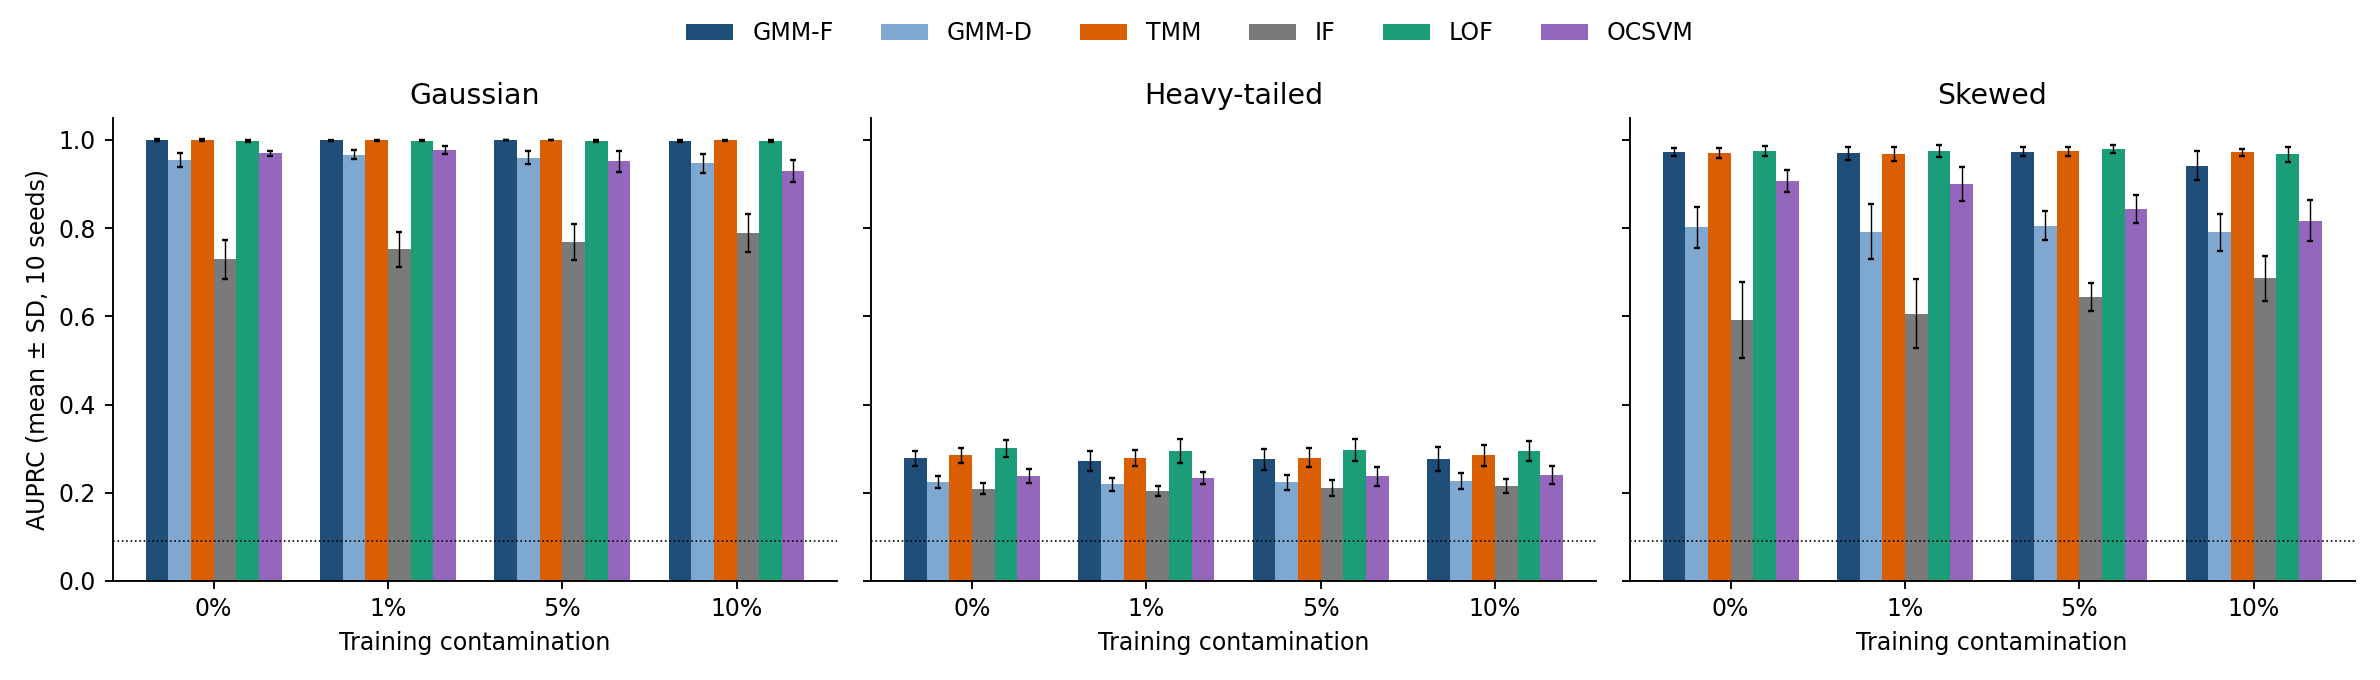

fig4_dimension


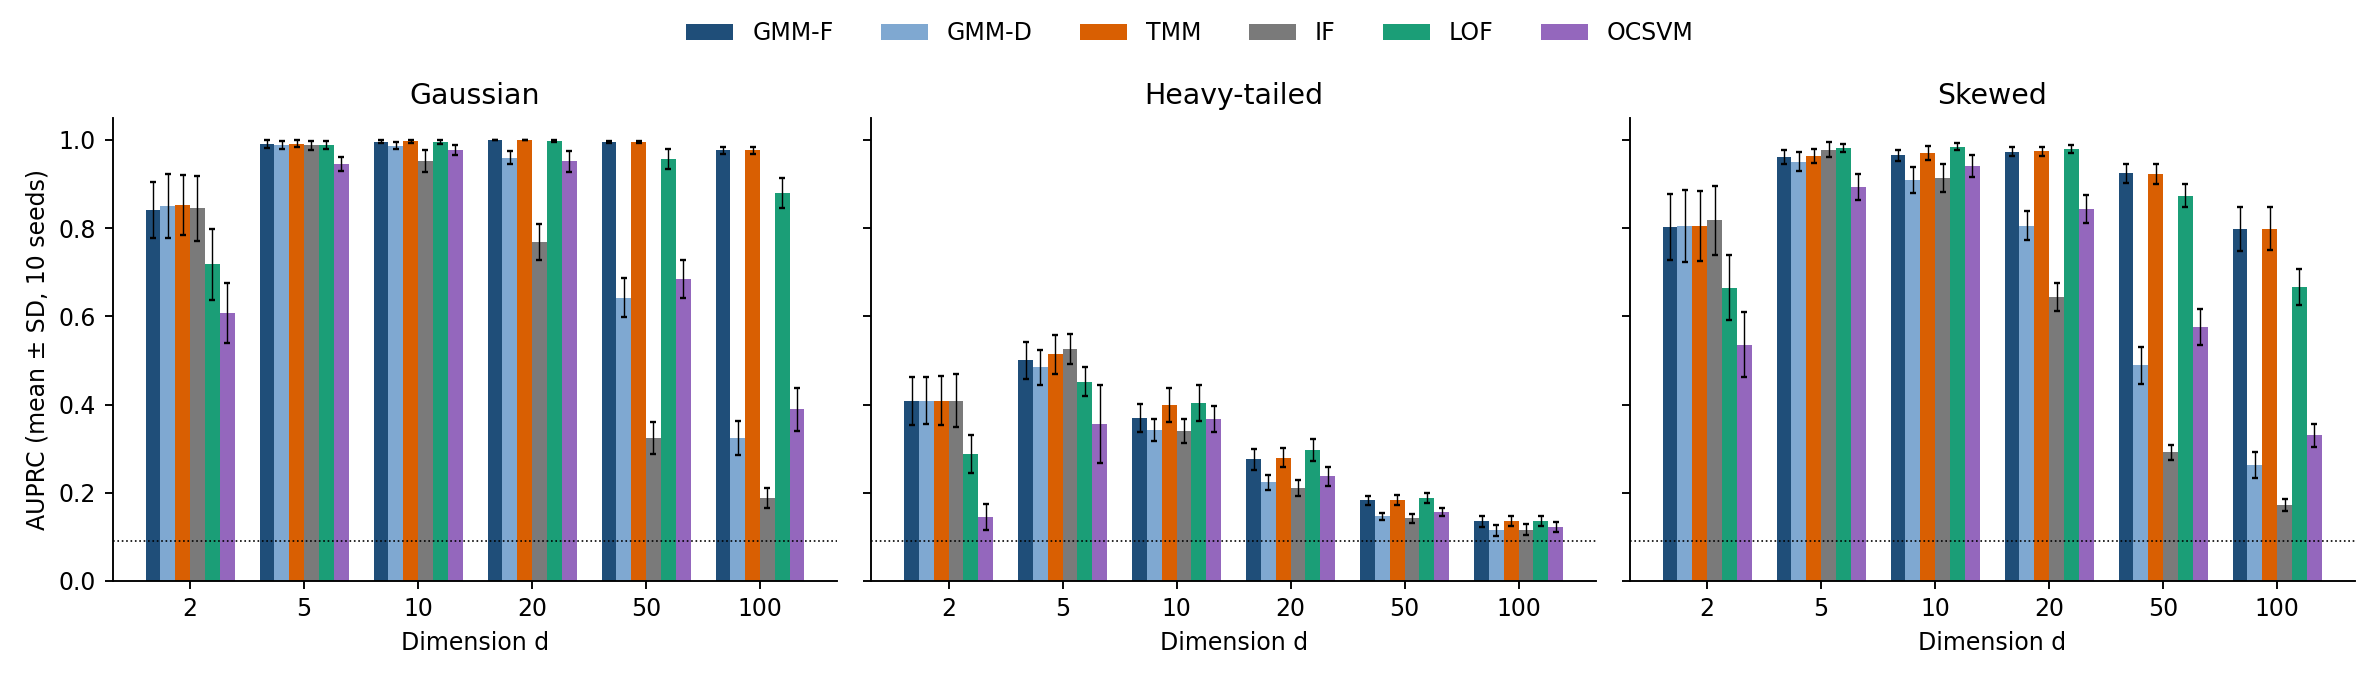

fig5_f1_dimension


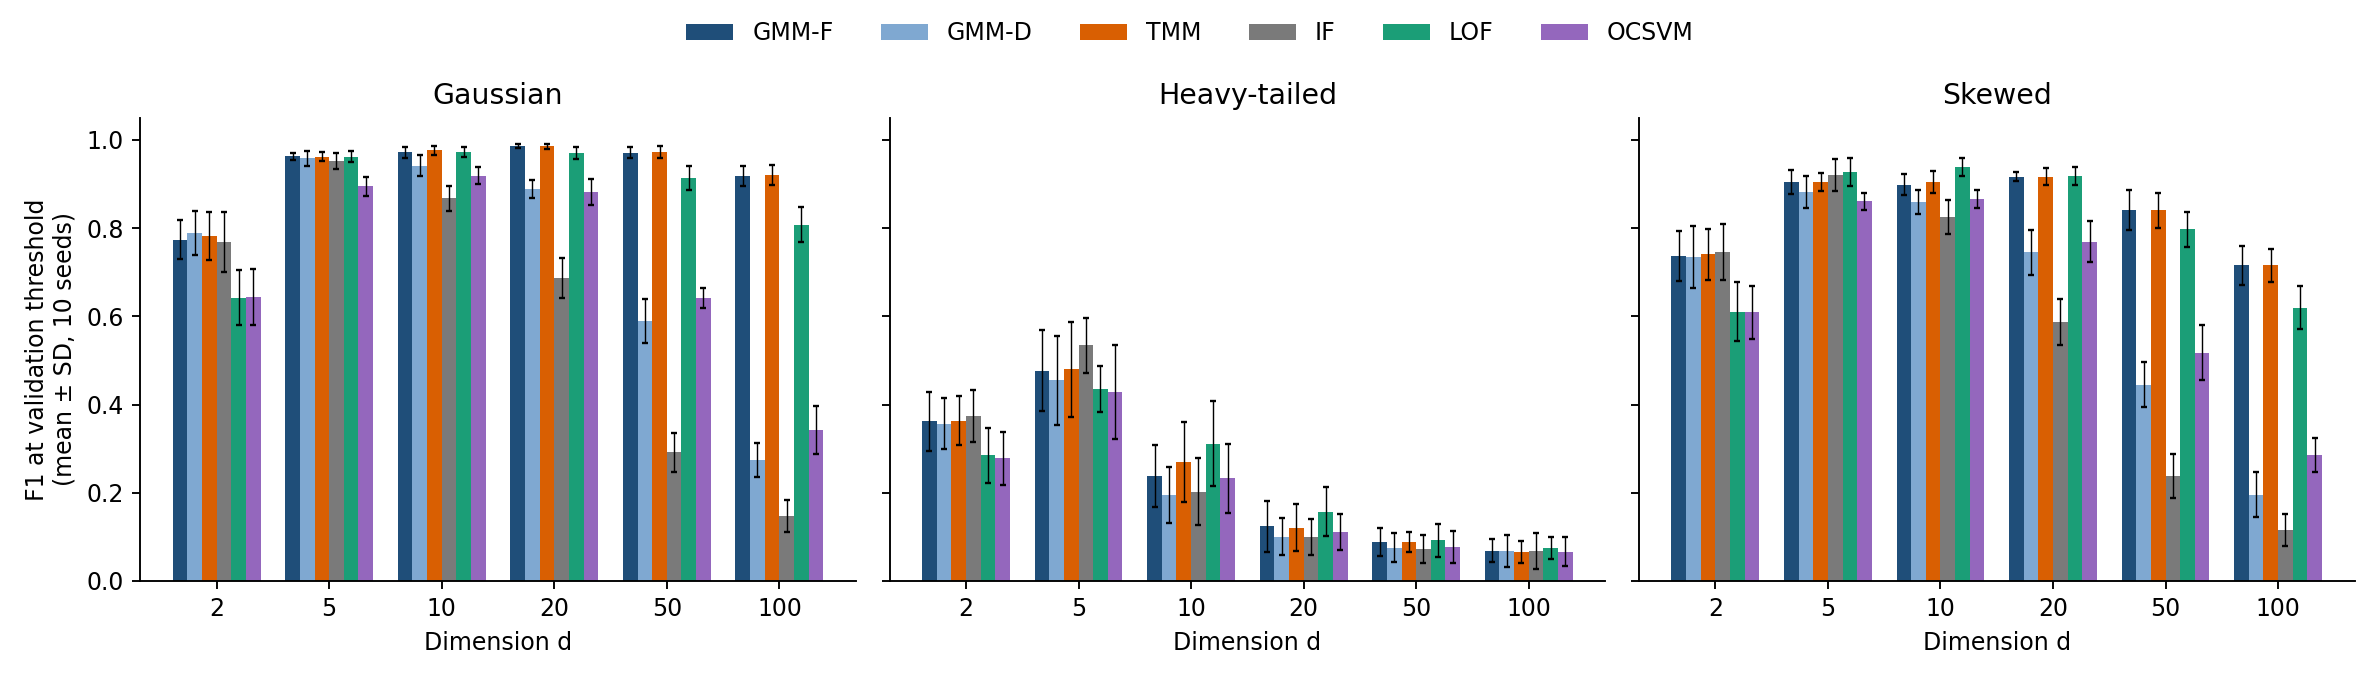

fig6_paired_difference


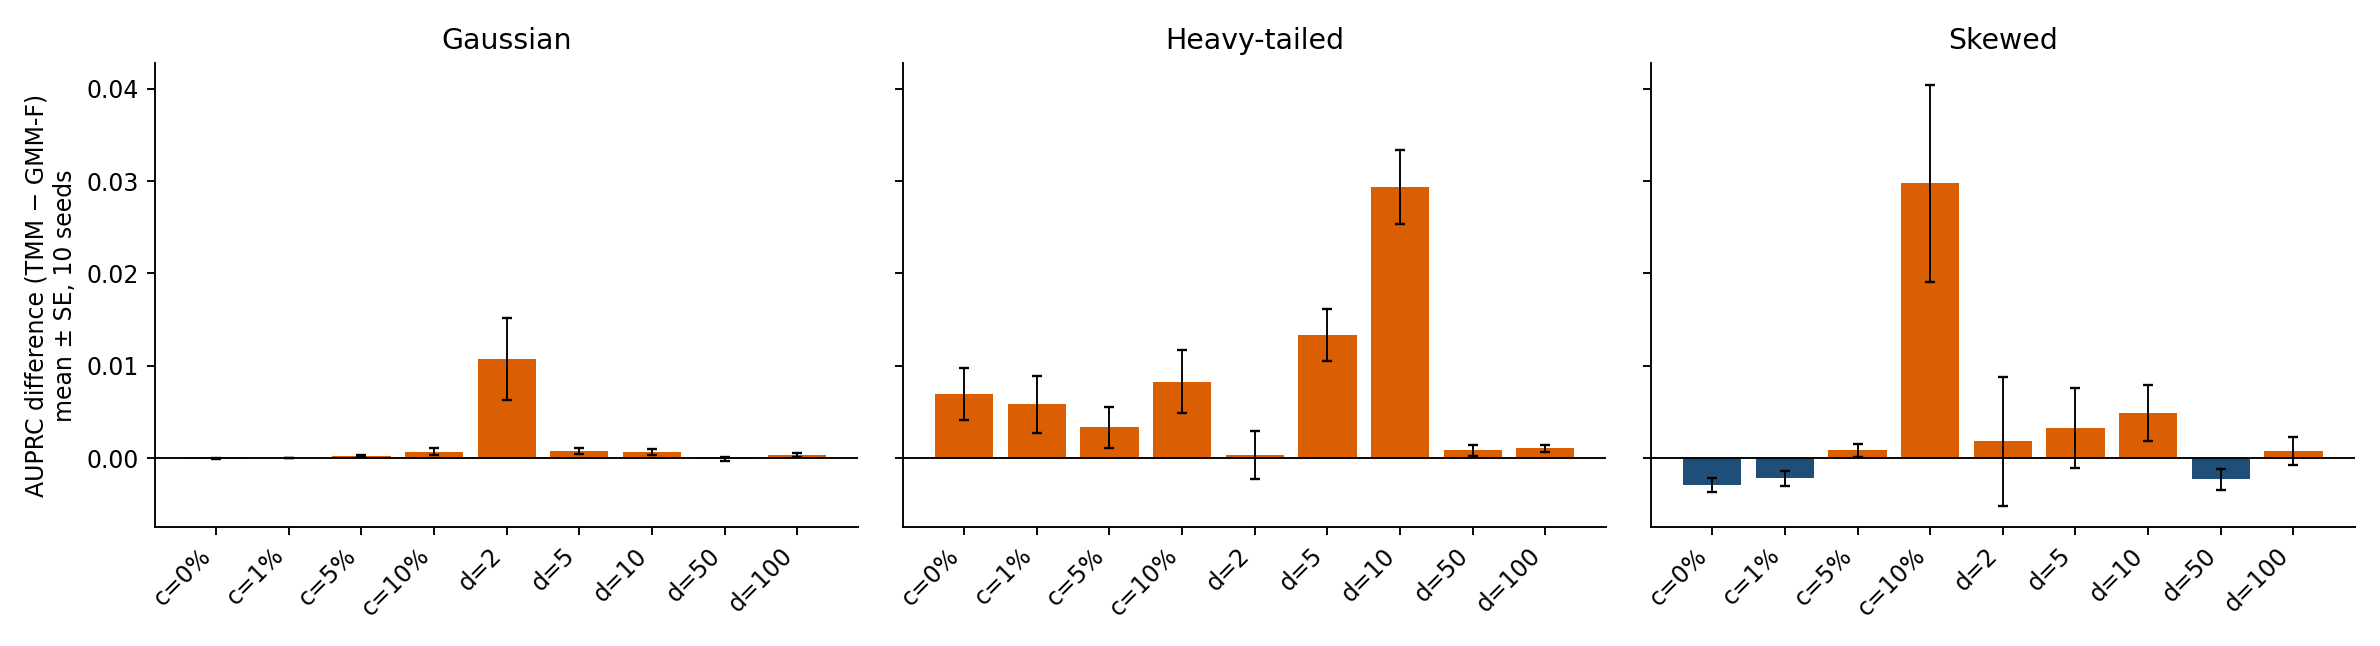

In [ ]:
from IPython.display import Image, display
for f in ['fig3_contamination','fig4_dimension','fig5_f1_dimension','fig6_paired_difference']:
    print(f)
    display(Image(f'results/{f}.png'))

### Step 4: show the tables

In [ ]:
import pandas as pd
for t in ['table_auprc_contamination','table_auprc_dimension','table_threshold_metrics','table_paired_comparison','table_runtime']:
    print(t)
    display(pd.read_csv(f'results/{t}.csv'))

table_auprc_contamination


,Data,Contam.,GMM-F,GMM-D,TMM,IF,LOF,OCSVM
0,Gaussian,0%,0.999,0.954,0.999,0.729,0.997,0.970
1,Gaussian,1%,0.999,0.966,0.999,0.752,0.998,0.977
2,Gaussian,5%,0.999,0.960,1.000,0.769,0.998,0.952
3,Gaussian,10%,0.998,0.947,0.999,0.789,0.997,0.930
4,Heavy,0%,0.278,0.224,0.285,0.209,0.300,0.239
5,Heavy,1%,0.272,0.219,0.278,0.204,0.294,0.234
6,Heavy,5%,0.276,0.224,0.279,0.211,0.296,0.238
7,Heavy,10%,0.276,0.226,0.284,0.215,0.295,0.241
8,Skewed,0%,0.973,0.801,0.970,0.591,0.975,0.907
9,Skewed,1%,0.969,0.792,0.967,0.606,0.974,0.900


table_auprc_dimension


,Data,d,GMM-F,GMM-D,TMM,IF,LOF,OCSVM
0,Gaussian,2,0.842,0.850,0.852,0.845,0.718,0.607
1,Gaussian,5,0.991,0.988,0.991,0.988,0.989,0.946
2,Gaussian,10,0.996,0.987,0.997,0.952,0.995,0.977
3,Gaussian,20,0.999,0.960,1.000,0.769,0.998,0.952
4,Gaussian,50,0.995,0.642,0.995,0.324,0.957,0.685
5,Gaussian,100,0.976,0.323,0.977,0.188,0.879,0.389
6,Heavy,2,0.408,0.408,0.409,0.409,0.288,0.145
7,Heavy,5,0.500,0.484,0.514,0.526,0.452,0.355
8,Heavy,10,0.369,0.341,0.398,0.340,0.403,0.367
9,Heavy,20,0.276,0.224,0.279,0.211,0.296,0.238


table_threshold_metrics


,Data,Model,Precision,Recall,F1,FPR
0,Gaussian,GMM-F,0.981,0.990,0.986,0.002
1,Gaussian,GMM-D,0.910,0.870,0.888,0.009
2,Gaussian,TMM,0.979,0.992,0.985,0.002
3,Gaussian,IF,0.771,0.629,0.687,0.019
4,Gaussian,LOF,0.976,0.966,0.970,0.003
5,Gaussian,OCSVM,0.900,0.867,0.882,0.010
6,Heavy,GMM-F,0.165,0.103,0.124,0.048
7,Heavy,GMM-D,0.134,0.084,0.101,0.052
8,Heavy,TMM,0.163,0.100,0.121,0.048
9,Heavy,IF,0.134,0.082,0.100,0.051


table_paired_comparison


,Condition,Mean diff. (TMM - GMM-F),Seeds TMM wins,p (Wilcoxon)
0,"Skewed, d = 20, 10% contam.",+0.030,10/10,0.002
1,"Heavy, d = 10, 5% contam.",+0.029,10/10,0.002
2,"Heavy, d = 5, 5% contam.",+0.013,9/10,0.004
3,"Heavy, d = 20, 10% contam.",+0.008,9/10,0.006
4,"Skewed, d = 20, 0% contam.",-0.003,1/10,0.010
5,"Gaussian, d = 2, 5% contam.",+0.011,9/10,0.020
6,"Gaussian, d = 20, any contam.",at most +0.001,2 to 6/10,0.055 to 0.625


table_runtime


,d,GMM-F,GMM-D,TMM,IF,LOF,OCSVM
0,2,0.197,0.110,0.256,0.478,0.027,0.038
1,20,0.538,0.091,0.251,0.498,0.077,0.047
2,50,0.604,0.099,0.620,0.495,0.096,0.054
3,100,0.801,0.209,1.656,0.515,0.130,0.071


### Step 5: download everything (tables as .csv/.md/.tex, figures as .png, raw results)

In [ ]:
!zip -rq results.zip results
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Optional: run on your own dataset
Upload a CSV, then edit the file name, label column and anomaly value.

```python
files.upload()
!python mixture_anomaly_full.py real --csv yourfile.csv --label-col label --anomaly-value 1 --protocol semi
```
Quick test with no upload: `!python mixture_anomaly_full.py real --demo breast_cancer`